In [1]:
# Step 1: Load and inspect

In [2]:
import pandas as pd

df = pd.read_csv("../data/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(df.shape)

(180519, 53)


In [3]:
# Step 2: Missing values

In [4]:
# Q: Which columns have missing values, and how many?
# Exp: Product Description 180519, Order Zipcode 155679, Customer Lname 8, Customer Zipcode 3. All other columns 0.

print(df.isna().sum())

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [5]:
# Step 3: Remove columns

In [6]:
# Q: Which columns do we remove, and how many columns are left?
# Exp: (180519, 43). 6 privacy columns and 4 columns that are empty or not needed for the questions are removed.

drop_cols = [
    "Customer Email", "Customer Fname", "Customer Lname", "Customer Password",
    "Customer Street", "Customer Zipcode",
    "Product Description", "Order Zipcode", "Latitude", "Longitude",
]

keep = []
for col in df.columns:
    if col not in drop_cols:
        keep.append(col)

df_clean = df.loc[:, keep]
print(df_clean.shape)

(180519, 43)


In [7]:
# Step 4: Duplicates check

In [8]:
# Q: How many rows share the same Order Item Id?
# Exp: 0 (no duplicate order items).

unique_items = df_clean.drop_duplicates(subset=["Order Item Id"])
print(len(df_clean) - len(unique_items))

0


In [9]:
# Step 5: Dates to datetime, time range

In [10]:
# Q: What is the date range of the orders, and how many orders per year?
# Exp: Min and max dates printed (2015-01-01 to 2018-01-31). 2018 should be a partial year.

df_clean["order date"] = pd.to_datetime(df_clean["order date (DateOrders)"])
df_clean["shipping date"] = pd.to_datetime(df_clean["shipping date (DateOrders)"])

print(df_clean["order date"].min(), df_clean["order date"].max())
print(df_clean["order date"].dt.year.value_counts())

2015-01-01 00:00:00 2018-01-31 23:38:00
order date
2015    62650
2016    62550
2017    53196
2018     2123
Name: count, dtype: int64


In [11]:
# Step 6: Date logic checks

In [12]:
# Q: How many orders have a shipping date before the order date?
# Exp: 0

gap_days = (df_clean["shipping date"] - df_clean["order date"]).dt.days
print((gap_days < 0).sum())

0


In [13]:
# Step 7: Date gap vs real shipping days

In [14]:
# Q: How many rows have a date gap that does not match "Days for shipping (real)"?
# Exp: 0 if the two sources agree. Any other number needs a closer look before we continue.

mismatch = gap_days != df_clean["Days for shipping (real)"]
print(mismatch.sum())

4657


In [15]:
# Step 8: Investigate date gap mismatches

In [16]:
# Q: In which shipping modes do the mismatches happen?
# Exp: Only one mode should have mismatches.

print(mismatch.groupby(df_clean["Shipping Mode"]).sum())

Shipping Mode
First Class          0
Same Day          4657
Second Class         0
Standard Class       0
dtype: int64


In [17]:
# Step 9: Same Day rows check

In [18]:
# Q: For Same Day rows, what are the real days and the date gap?
# Exp: The mismatched rows should have real days = 1 and date gap = 0. This is a hypothesis to test.

same_day = df_clean["Shipping Mode"] == "Same Day"
print(df_clean.loc[same_day, "Days for shipping (real)"].value_counts())
print(gap_days[same_day].value_counts())

Days for shipping (real)
0    5080
1    4657
Name: count, dtype: int64
0    9737
Name: count, dtype: int64


In [19]:
# Step 10: Delay days

In [20]:
# Q: What is the delay per order (real days minus scheduled days), and how is it spread?
# Exp: Positive = late, zero = on time, negative = early.

df_clean["delay_days"] = df_clean["Days for shipping (real)"] - df_clean["Days for shipment (scheduled)"]
print(df_clean["delay_days"].value_counts())

delay_days
 1    60647
 0    33753
 2    28718
-1    21700
-2    21666
 3     7052
 4     6983
Name: count, dtype: int64


In [21]:
# Step 11: Check late definition

In [22]:
# Q: Do delay_days > 0 and Late_delivery_risk = 1 describe the same orders?
# Exp: The counts differ only because of canceled orders. The groupby shows which Delivery Status causes the gap.

late_by_delay = df_clean["delay_days"] > 0
print(late_by_delay.sum())
print(df_clean["Late_delivery_risk"].sum())
print(late_by_delay.groupby(df_clean["Delivery Status"]).sum())

103400
98977
Delivery Status
Advance shipping         0
Late delivery        98977
Shipping canceled     4423
Shipping on time         0
Name: delay_days, dtype: int64


In [23]:
# Step 12: Delivered orders subset

In [24]:
# Q: How many orders were delivered (not canceled), and how many of them were late?
# Exp: 172,765 delivered orders, 98,977 of them late.

delivered = df_clean[df_clean["Delivery Status"] != "Shipping canceled"]
print(len(delivered))
print(delivered["Late_delivery_risk"].sum())

172765
98977


In [25]:
# Step 13: late rate and average delay by mode

In [26]:
# Q: For delivered orders, what is the late rate and the average delay for each shipping mode?
# Exp: First Class has the highest late rate (100%).

print(delivered["Late_delivery_risk"].groupby(delivered["Shipping Mode"]).mean() * 100)
print(delivered["delay_days"].groupby(delivered["Shipping Mode"]).mean())

Shipping Mode
First Class       100.000000
Same Day           47.928548
Second Class       79.829024
Standard Class     39.769081
Name: Late_delivery_risk, dtype: float64
Shipping Mode
First Class       1.000000
Same Day          0.479285
Second Class      1.993167
Standard Class   -0.006301
Name: delay_days, dtype: float64


In [27]:
# Step 14: is the delay fixed per mode?

In [28]:
# Q: For delivered orders, is the delay fixed for each shipping mode?
# Exp: A fixed promise shows one value only. A spread shows several values.

for mode in ["First Class", "Second Class", "Same Day", "Standard Class"]:
    mode_rows = delivered["Shipping Mode"] == mode
    print(mode)
    print(delivered.loc[mode_rows, "delay_days"].value_counts())

First Class
delay_days
1    26513
Name: count, dtype: int64
Second Class
delay_days
0    6819
3    6772
1    6759
2    6759
4    6697
Name: count, dtype: int64
Same Day
delay_days
0    4839
1    4454
Name: count, dtype: int64
Standard Class
delay_days
-2    20873
 2    20792
-1    20719
 0    20538
 1    20231
Name: count, dtype: int64


In [29]:
# Step 15: discount and loss share

In [30]:
# Q: Is the share of loss-making orders higher for discounted orders than for non-discounted orders?
# Exp: If discounts drive losses, the discounted share will be clearly higher. Also check the group sizes.

has_discount = df_clean["Order Item Discount Rate"] > 0
no_discount = df_clean["Order Item Discount Rate"] == 0
loss = df_clean["Order Profit Per Order"] < 0

print(loss[has_discount].mean() * 100)
print(loss[no_discount].mean() * 100)

# Validation: group sizes
print(has_discount.sum(), no_discount.sum())

18.734713269322135
18.37854008775429
170491 10028


In [31]:
# Step 16: segment profit and sales

In [32]:
# Q: Which customer segment has the highest average profit per order and the highest total sales?
# Exp: One value per segment for each measure.

segment_totals = df_clean["Sales"].groupby(df_clean["Customer Segment"]).sum()

print(df_clean["Order Profit Per Order"].groupby(df_clean["Customer Segment"]).mean())
print(segment_totals)

Customer Segment
Consumer       22.175390
Corporate      21.949204
Home Office    21.437359
Name: Order Profit Per Order, dtype: float64
Customer Segment
Consumer       1.909579e+07
Corporate      1.116841e+07
Home Office    6.520538e+06
Name: Sales, dtype: float64


In [33]:
# Step 17: validation

In [34]:
# Q: Do the segment sales totals add up to the overall sales total?
# Exp: The difference is 0.0 (or a tiny floating-point amount).

print(df_clean["Sales"].sum())
print(segment_totals.sum() - df_clean["Sales"].sum())

36784735.01337984
0.0


In [35]:
# Step 18: late rate by shipping mode

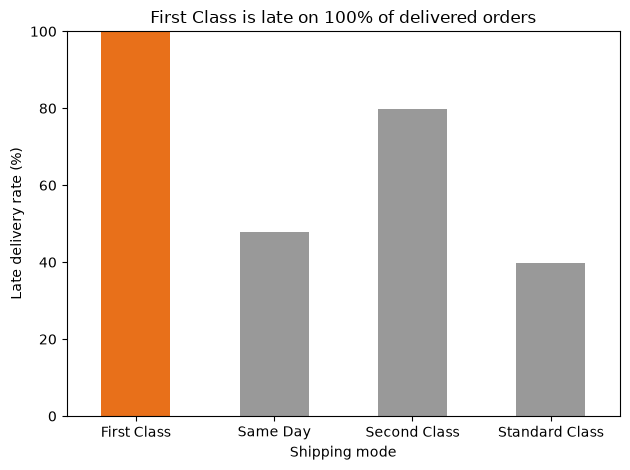

In [36]:
# Q: Which shipping mode has the highest late rate among delivered orders?
# Exp: Four bars. First Class is the tallest at 100%.

import matplotlib.pyplot as plt

late_rate = delivered["Late_delivery_risk"].groupby(delivered["Shipping Mode"]).mean() * 100

late_rate.plot(kind="bar", color=["#E8701A", "#999999", "#999999", "#999999"])
plt.title("First Class is late on 100% of delivered orders")
plt.ylabel("Late delivery rate (%)")
plt.xlabel("Shipping mode")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("../images/chart1_late_rate_by_mode.png", dpi=150)
plt.show()

In [37]:
# Step 19: discount vs loss share

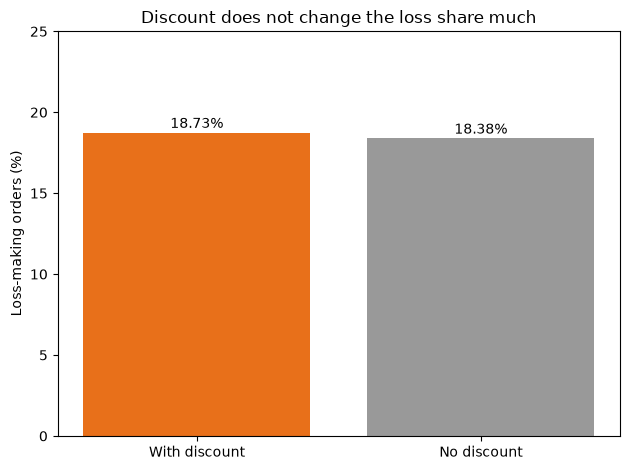

In [38]:
# Q: Is the loss-making share different for discounted and non-discounted orders?
# Exp: Two bars of similar height. The difference is small, so the chart should look flat.

discount_share = loss[has_discount].mean() * 100
no_discount_share = loss[no_discount].mean() * 100
shares = [discount_share, no_discount_share]
labels = ["With discount", "No discount"]

plt.bar(labels, shares, color=["#E8701A", "#999999"])
for i, value in enumerate(shares):
    plt.text(i, value + 0.3, f"{value:.2f}%", ha="center")

plt.title("Discount does not change the loss share much")
plt.ylabel("Loss-making orders (%)")
plt.ylim(0, 25)
plt.tight_layout()
plt.savefig("../images/chart2_discount_vs_loss.png", dpi=150)
plt.show()

In [39]:
# Step 20: sales by segment

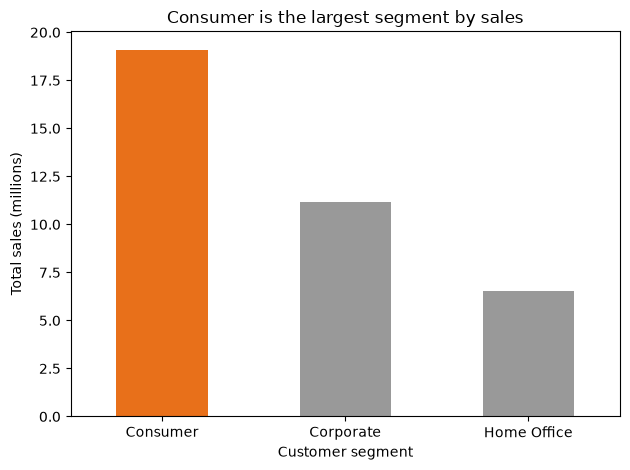

In [40]:
# Q: Which customer segment has the highest total sales?
# Exp: Consumer is the tallest bar, followed by Corporate and Home Office. Y-axis is in millions.

(segment_totals / 1_000_000).plot(kind="bar", color=["#E8701A", "#999999", "#999999"])
plt.title("Consumer is the largest segment by sales")
plt.ylabel("Total sales (millions)")
plt.xlabel("Customer segment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/chart3_sales_by_segment.png", dpi=150)
plt.show()

In [41]:
# Step 21: First Class real vs scheduled days (delivered orders)

In [42]:
# Q: For delivered First Class orders, what are the average real shipping days and the average scheduled days?
# Exp: Two numbers. Compare them with the delay result from Step 13.

first_class_delivered = delivered[delivered["Shipping Mode"] == "First Class"]
print(first_class_delivered["Days for shipping (real)"].mean())
print(first_class_delivered["Days for shipment (scheduled)"].mean())

2.0
1.0
